In [ ]:
%pip install -U "torchao==0.18.0"

In [21]:
import time
import pandas as pd
import torch
import torchao

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Trainer,
    TrainingArguments,
    DataCollatorForLanguageModeling,
    set_seed,
)
from peft import LoraConfig, TaskType, get_peft_model

# Experiment settings
MODEL_NAME = "distilgpt2"
RANKS = [1, 2, 4, 8, 16, 32, 64, 128]
SEED = 42

# Fixed compute budget for each experiment
MAX_STEPS = 100
BATCH_SIZE = 4
LEARNING_RATE = 2e-4
MAX_LENGTH = 128

set_seed(SEED)

# Load dataset and tokenizer once
raw = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

# Remove blank lines and select reproducible subsets
train_raw = raw["train"].filter(
    lambda x: len(x["text"].strip()) > 0
).shuffle(seed=SEED).select(range(1000))

valid_raw = raw["validation"].filter(
    lambda x: len(x["text"].strip()) > 0
).select(range(200))

train_data = train_raw.map(
    tokenize, batched=True, remove_columns=["text"]
)
valid_data = valid_raw.map(
    tokenize, batched=True, remove_columns=["text"]
)

collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False,
)

results = []

# Baseline
print("\nBaseline: pretrained model, no fine-tuning")

set_seed(SEED)
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
base_model.config.pad_token_id = tokenizer.pad_token_id

base_args = TrainingArguments(
    output_dir="./results/baseline",
    per_device_eval_batch_size=BATCH_SIZE,
    report_to="none",
    seed=SEED,
)

base_trainer = Trainer(
    model=base_model,
    args=base_args,
    eval_dataset=valid_data,
    data_collator=collator,
)

base_loss = base_trainer.evaluate()["eval_loss"]

baseline_rows = [{
    "rank": "baseline (no FT)",
    "trainable_params": 0,
    "train_seconds": 0.0,
    "eval_loss": base_loss,
    "perplexity": float(torch.exp(torch.tensor(base_loss))) if base_loss < 80 else float("inf"),
}]

del base_trainer, base_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

RUN_FULL_FT = True  # set False to skip

if RUN_FULL_FT:
    print("\nBaseline: full fine-tuning")

    set_seed(SEED)
    full_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
    full_model.config.pad_token_id = tokenizer.pad_token_id

    full_params = sum(p.numel() for p in full_model.parameters() if p.requires_grad)

    full_args = TrainingArguments(
        output_dir="./results/full_ft",
        max_steps=MAX_STEPS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        learning_rate=5e-5,  # full FT needs a lower LR than LoRA
        lr_scheduler_type="linear",
        warmup_steps=10,
        eval_strategy="no",
        save_strategy="no",
        logging_strategy="no",
        report_to="none",
        seed=SEED,
        data_seed=SEED,
    )

    full_trainer = Trainer(
        model=full_model,
        args=full_args,
        train_dataset=train_data,
        eval_dataset=valid_data,
        data_collator=collator,
    )

    start = time.perf_counter()
    full_trainer.train()
    full_seconds = time.perf_counter() - start

    full_loss = full_trainer.evaluate()["eval_loss"]

    baseline_rows.append({
        "rank": "full fine-tune",
        "trainable_params": full_params,
        "train_seconds": round(full_seconds, 2),
        "eval_loss": full_loss,
        "perplexity": float(torch.exp(torch.tensor(full_loss))) if full_loss < 80 else float("inf"),
    })

    del full_trainer, full_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

for rank in RANKS:
    print(f"\nExperiment: LoRA rank = {rank}")

    set_seed(SEED)

    # Reload the original model for a fair comparison
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
    model.config.pad_token_id = tokenizer.pad_token_id

    config = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=rank,
        lora_alpha=16,
        lora_dropout=0.1,
        target_modules=["c_attn"],
    )

    model = get_peft_model(model, config)
    model.print_trainable_parameters()

    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    args = TrainingArguments(
        output_dir=f"./results/rank_{rank}",
        max_steps=MAX_STEPS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        lr_scheduler_type="linear",
        warmup_steps=10,
        eval_strategy="no",
        save_strategy="no",
        logging_strategy="no",
        report_to="none",
        seed=SEED,
        data_seed=SEED,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_data,
        eval_dataset=valid_data,
        data_collator=collator,
    )

    start = time.perf_counter()
    trainer.train()
    train_seconds = time.perf_counter() - start

    metrics = trainer.evaluate()
    eval_loss = metrics["eval_loss"]

    # Perplexity = exp(validation loss)
    perplexity = (
        float(torch.exp(torch.tensor(eval_loss)))
        if eval_loss < 80 else float("inf")
    )

    results.append({
        "rank": rank,
        "trainable_params": trainable_params,
        "train_seconds": round(train_seconds, 2),
        "eval_loss": eval_loss,
        "perplexity": perplexity,
    })

    model.save_pretrained(f"./adapters/rank_{rank}")

    del trainer, model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Compare results
df = pd.concat(    [pd.DataFrame(baseline_rows), pd.DataFrame(results).sort_values("rank")], ignore_index=True)
print("\nExperiment results:")
print(df.to_string(index=False))
df.to_csv("lora_rank_results.csv", index=False)



Baseline: pretrained model, no fine-tuning


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Training Loss,Validation Loss,Step
No log,4.337072,0



Baseline: full fine-tuning


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

...

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 2,359,296 || all params: 84,271,872 || trainable%: 2.7996


Step,Training Loss


Training Loss,Validation Loss,Step
No log,4.125907,100



Experiment results:
            rank  trainable_params  train_seconds  eval_loss  perplexity
baseline (no FT)                 0           0.00   4.337072   76.483299
  full fine-tune          81912576          13.19   3.729428   41.655258
               1             18432           8.32   4.123084   61.749390
               2             36864           8.48   4.135198   62.501942
               4             73728           8.37   4.114847   61.242825
               8            147456           6.83   4.125601   61.905022
              16            294912           6.72   4.127872   62.045719
              32            589824           6.62   4.124873   61.859962
              64           1179648           6.63   4.126005   61.930027
             128           2359296           6.72   4.125907   61.923973


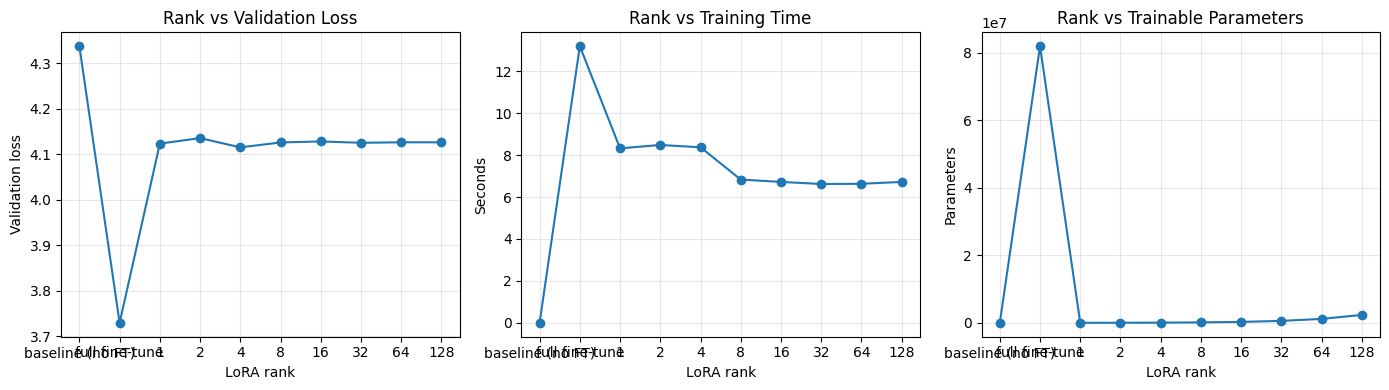

In [22]:
import matplotlib.pyplot as plt

df = pd.read_csv("lora_rank_results.csv")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(df["rank"], df["eval_loss"], marker="o")
axes[0].set_title("Rank vs Validation Loss")
axes[0].set_ylabel("Validation loss")

axes[1].plot(df["rank"], df["train_seconds"], marker="o")
axes[1].set_title("Rank vs Training Time")
axes[1].set_ylabel("Seconds")

axes[2].plot(
    df["rank"], df["trainable_params"], marker="o"
)
axes[2].set_title("Rank vs Trainable Parameters")
axes[2].set_ylabel("Parameters")

for ax in axes:
    ax.set_xlabel("LoRA rank")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
